# Sophie Data Exploration
## Intensity datasets

Files: `dailyIntensities`, `hourlyIntensities`, `minuteIntensitiesNarrow`, `minuteIntensitiesWide`

Notes:
- All use the same scale: 0 = sedentary, 1 = light, 2 = moderate and 3 = vigorous.
- Daily gives minutes in each band per day, plus distance covered at each intensity
- Hourly gives the intensity score (0–180) for each hour, so you can see when in the day people are active
- Minute (narrow and wide) is the raw minute-by-minute stream. Narrow and wide are the same data
- They show when people are active not just how much 
- There are 33 users over 31 days, 12 April to 12 May 2016. 
- The intensity files have no missing values 
- Hourly totals equal the sum of the minute values exactly so the files are consistent and safe to aggregate
- Since the audience is a friend group of athletes we will focused on what helps people track goals, compare themselves to each other and stay motivated.

In [1]:
# imports
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

repo = next(p for p in [Path.cwd()] + list(Path.cwd().parents) if p.name == "DATA2007-Fitbit-Dashboard-Group")
FOLDER = repo / "datafolder" / "FitBit Dataset-20261009"
DATETIME = "%m/%d/%Y %I:%M:%S %p"  # US format month first
DATE = "%m/%d/%Y"

In [3]:
# csv
daily         = pd.read_csv(FOLDER / "dailyIntensities_merged.csv")
hourly        = pd.read_csv(FOLDER / "hourlyIntensities_merged.csv")
minute_narrow = pd.read_csv(FOLDER / "minuteIntensitiesNarrow_merged.csv")
minute_wide   = pd.read_csv(FOLDER / "minuteIntensitiesWide_merged.csv")

### Format time columns types

In [4]:
daily["ActivityDay"] = pd.to_datetime(daily["ActivityDay"], format=DATE)
hourly["ActivityHour"] = pd.to_datetime(hourly["ActivityHour"], format=DATETIME)
minute_narrow["ActivityMinute"] = pd.to_datetime(
    minute_narrow["ActivityMinute"], format=DATETIME
)
minute_wide["ActivityHour"] = pd.to_datetime(
    minute_wide["ActivityHour"], format=DATETIME
)

### Overview of the data

In [5]:
# combine datasets
datasets = {
    "daily": {"df": daily, "time_col": "ActivityDay"},
    "hourly": {"df": hourly, "time_col": "ActivityHour"},
    "minute narrow": {"df": minute_narrow, "time_col": "ActivityMinute"},
    "minute wide": {"df": minute_wide, "time_col": "ActivityHour"},
}

overview = pd.DataFrame(
    {
        "rows": {name: len(info["df"]) for name, info in datasets.items()},
        "columns": {name: info["df"].shape[1] for name, info in datasets.items()},
        "time column": {name: info["time_col"] for name, info in datasets.items()},
    }
)
print(overview)

                  rows  columns     time column
daily              940       10     ActivityDay
hourly           22099        4    ActivityHour
minute narrow  1325580        3  ActivityMinute
minute wide      21645       62    ActivityHour


### Check for missing values

In [6]:
for name, info in datasets.items():
    missing_per_column = info["df"].isna().sum()  
    total_missing = missing_per_column.sum()

    print(f"{name:14s} total missing: {total_missing}")
    if total_missing > 0:  # only list columns that have a problem
        print(missing_per_column[missing_per_column > 0])

daily          total missing: 0
hourly         total missing: 0
minute narrow  total missing: 0
minute wide    total missing: 0


### Do files cover the same people

In [7]:
# The set of user IDs in the daily file is our reference
daily_users = set(daily["Id"])

# Compare every file's users to the reference
for name, info in datasets.items():
    users = set(info["df"]["Id"])
    print(f"{name:14s} {len(users)} users, same as daily? {users == daily_users}")

daily          33 users, same as daily? True
hourly         33 users, same as daily? True
minute narrow  33 users, same as daily? True
minute wide    33 users, same as daily? True


### Data exploration

Understanding the categories

In [8]:
minute_cols = [
    "SedentaryMinutes",
    "LightlyActiveMinutes",
    "FairlyActiveMinutes",
    "VeryActiveMinutes",
]
distance_cols = [
    "SedentaryActiveDistance",
    "LightActiveDistance",
    "ModeratelyActiveDistance",
    "VeryActiveDistance",
]

# New columns, one value per row (per person per day)
daily["TotalMinutes"] = daily[minute_cols].sum(axis=1)
daily["ActiveMinutes"] = (
    daily["LightlyActiveMinutes"]
    + daily["FairlyActiveMinutes"]
    + daily["VeryActiveMinutes"]
)
daily["ModVigMinutes"] = daily["FairlyActiveMinutes"] + daily["VeryActiveMinutes"]
daily["TotalActiveDistance"] = daily[distance_cols].sum(axis=1)

# Summary table: one row per column
summary = daily[minute_cols + distance_cols].describe().T.round(2)
print(summary)

##### NEEED TO UNDESTAND THIS OUTPUT TABLE BETTER - WHY IS THE COUNT ALWAYS 940?

                          count    mean     std  min     25%      50%  \
SedentaryMinutes          940.0  991.21  301.27  0.0  729.75  1057.50   
LightlyActiveMinutes      940.0  192.81  109.17  0.0  127.00   199.00   
FairlyActiveMinutes       940.0   13.56   19.99  0.0    0.00     6.00   
VeryActiveMinutes         940.0   21.16   32.84  0.0    0.00     4.00   
SedentaryActiveDistance   940.0    0.00    0.01  0.0    0.00     0.00   
LightActiveDistance       940.0    3.34    2.04  0.0    1.95     3.36   
ModeratelyActiveDistance  940.0    0.57    0.88  0.0    0.00     0.24   
VeryActiveDistance        940.0    1.50    2.66  0.0    0.00     0.21   

                              75%      max  
SedentaryMinutes          1229.50  1440.00  
LightlyActiveMinutes       264.00   518.00  
FairlyActiveMinutes         19.00   143.00  
VeryActiveMinutes           32.00   210.00  
SedentaryActiveDistance      0.00     0.11  
LightActiveDistance          4.78    10.71  
ModeratelyActiveDistance   

### How much was the tracker worn?

In [9]:
FULL_DAY = 1440  # minutes in a day

full_days = (daily["TotalMinutes"] == FULL_DAY).sum()
partial_days = (daily["TotalMinutes"] < FULL_DAY).sum()
over_days = (daily["TotalMinutes"] > FULL_DAY).sum()
print("Full days:", full_days, " Partial days:", partial_days)

not_worn = daily["SedentaryMinutes"] == FULL_DAY
print(
    "Not-worn days:",
    not_worn.sum(),
    "across",
    daily.loc[not_worn, "Id"].nunique(),
    "users",
)

Full days: 478  Partial days: 462
Not-worn days: 79 across 17 users


### Proportion of the day by intensity level

In [10]:
levels = ["Sedentary", "Light", "Moderate", "Vigorous"]
intensity_names = dict(enumerate(levels))  # 0 -> Sedentary, 1 -> Light, ...
daily_cols = {
    "SedentaryMinutes": "Sedentary",
    "LightlyActiveMinutes": "Light",
    "FairlyActiveMinutes": "Moderate",
    "VeryActiveMinutes": "Vigorous",
}

# Daily minutes with friendly column names, for all days and for worn days only
daily_minutes = daily.rename(columns=daily_cols)[levels]
worn_minutes = daily_minutes[daily["SedentaryMinutes"] != 1440]


def percent_share(minutes_table):
    """Each intensity level as a % of all recorded minutes."""
    totals = minutes_table.sum()
    return totals / totals.sum() * 100


summary = (
    pd.DataFrame(
        {
            "% of minutes": minute_narrow["Intensity"]
            .map(intensity_names)
            .value_counts(normalize=True)
            .mul(100),
            "% of time (daily, all days)": percent_share(daily_minutes),
            "% of time (daily, worn days)": percent_share(worn_minutes),
            "avg min/day (all days)": daily_minutes.mean(),
            "avg min/day (worn days)": worn_minutes.mean(),
            "median min/day (worn days)": worn_minutes.median(),
            "% worn days with 0 min": (worn_minutes == 0).mean() * 100,
        }
    )
    .loc[levels]
    .round(1)
)

summary.T  

,Sedentary,Light,Moderate,Vigorous
% of minutes,83.9,13.6,1.0,1.5
"% of time (daily, all days)",81.3,15.8,1.1,1.7
"% of time (daily, worn days)",79.3,17.6,1.2,1.9
avg min/day (all days),991.2,192.8,13.6,21.2
avg min/day (worn days),950.0,210.5,14.8,23.1
median min/day (worn days),1019.0,209.0,8.0,7.0
% worn days with 0 min,0.1,0.6,35.4,38.3


## Summary of findings:

- Most time is sedentary - on days the tracker was worn about 79% of time is sedentary (including sleep), 18% light activity and only about 3% moderate or vigorous.
- Activity is highly skewed - the typical day has about 8 moderate and 7 vigorous minutes but the means are 15 and 23, because a minority of very hard days pull the average up. About 38% of worn days have no vigorous activity.
- People differ widely - the share of days with 30+ hard minutes ranges from 0% to 96% and about 70% of full user-weeks meet the WHO target of 150 moderate-equivalent minutes.
- Routines vary - the group peaks at 5-7pm, but individual peaks split between morning (14 users), evening (13) and afternoon (6) Weekdays and weekends look similar overall.
- Consistency is also uneven - one user has 20 consecutive days above 10,000 steps, while another’s longest run is a single day.
- 79 user-days (17 users) are 100% sedentary, almost certainly a tracker not worn. 
- Many days are partly recorded (462 of 940 under 1,440 minutes) and one user has only 4 days.
- The final day (12 May) is incomplete, so we excluded it
- The minute-wide file duplicates the narrow file with slightly different coverage, so we will be dropping it
- Timestamps are US month-first 12-hour with no time zone.

# Intensity ideas for the dashboard:

In [11]:
daily["ModVigMinutes"] = daily["FairlyActiveMinutes"] + daily["VeryActiveMinutes"]
worn = daily[daily["SedentaryMinutes"] != 1440].copy()  # drop days the tracker wasn't worn

my_id = 1624580081     

## 1. “How did I do today and this week?” 
Show: moderate plus vigorous minutes today, this week, and against the 150-minute weekly target, as a progress bar.
Data: daily file.
Explore: how many users hit 150 a week, and how much that changes if you count vigorous minutes double (the WHO convention).

In [12]:
worn["Week"] = worn["ActivityDay"].dt.to_period("W")

weekly = worn.groupby(["Id", "Week"]).agg(
    days      = ("ActivityDay", "count"),
    moderate  = ("FairlyActiveMinutes", "sum"),
    vigorous  = ("VeryActiveMinutes", "sum"),
).reset_index()

weekly["who_minutes"] = weekly["moderate"] + 2 * weekly["vigorous"]   # vigorous counts double
weekly["hit_target"]  = weekly["who_minutes"] >= 150

print(weekly[weekly["Id"] == my_id])

full_weeks = weekly[weekly["days"] >= 6]                              # ignore part-weeks
print("Full weeks hitting 150:", round(full_weeks["hit_target"].mean() * 100), "%")

           Id                   Week  days  moderate  vigorous  who_minutes  \
5  1624580081  2016-04-11/2016-04-17     6        22        15           52   
6  1624580081  2016-04-18/2016-04-24     7        25        33           91   
7  1624580081  2016-04-25/2016-05-01     7       127       214          555   
8  1624580081  2016-05-02/2016-05-08     7         6         7           20   
9  1624580081  2016-05-09/2016-05-15     4         0         0            0   

   hit_target  
5       False  
6       False  
7        True  
8       False  
9       False  
Full weeks hitting 150: 70 %


## 2. “How do I compare to other users?”
Show: a leaderboard on a fair measure, and my position in the group distribution.
Data: daily file, with the non-wear and minimum-days filters.
Explore: which ranking measure is fair. Total active minutes rewards long, easy walks, while vigorous minutes rewards hard sessions. Letting the user toggle between them is a good dashboard feature.
Watch out: the data is skewed, so show medians. Users also have very different amounts of data (4 to 31 days), so show how many days each ranking is based on.

In [13]:
MIN_DAYS = 7     # hide users with too little data

board = worn.groupby("Id").agg(
    days      = ("ActivityDay", "count"),
    mod_vig   = ("ModVigMinutes", "median"),
    vigorous  = ("VeryActiveMinutes", "median"),
)
board = board[board["days"] >= MIN_DAYS]

board["rank_mod_vig"]  = board["mod_vig"].rank(ascending=False, method="min").astype(int)
board["rank_vigorous"] = board["vigorous"].rank(ascending=False, method="min").astype(int)

print(board.sort_values("rank_mod_vig").head(5))
print("Rank agreement:", round(board["mod_vig"].corr(board["vigorous"], method="spearman"), 2))

            days  mod_vig  vigorous  rank_mod_vig  rank_vigorous
Id                                                              
5577150313    28    104.0      92.0             1              1
8053475328    31    102.0      90.0             2              2
3977333714    30     86.0      14.5             3             12
8877689391    31     82.0      68.0             4              3
8378563200    31     80.0      65.0             5              4
Rank agreement: 0.97


## 3. “Am I improving?” 
Show: a line of daily active minutes with a 7-day average, with the group average for context.
Data: daily file.
Explore: whether a trend actually exists over a month, or whether it’s just noise. With 31 days, be careful about claiming one.

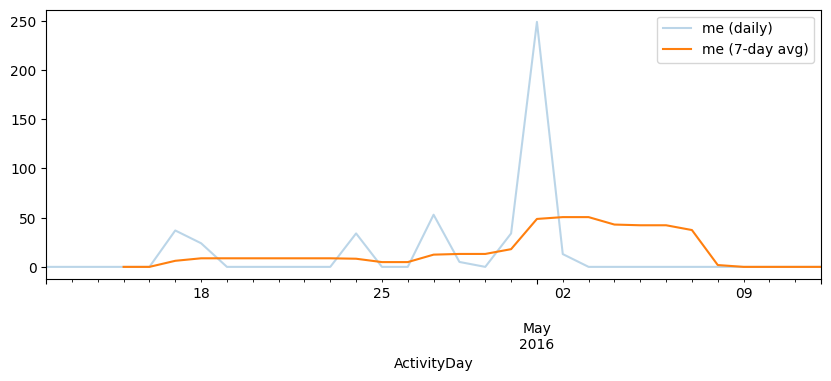

In [14]:
my_days     = worn[worn["Id"] == my_id].set_index("ActivityDay")["ModVigMinutes"]
my_trend    = my_days.rolling(7, min_periods=4).mean()
group_trend = worn.groupby("ActivityDay")["ModVigMinutes"].mean().rolling(7, min_periods=4).mean()

ax = my_days.plot(alpha=0.3, label="me (daily)", figsize=(10, 3.5))
my_trend.plot(ax=ax, label="me (7-day avg)")
ax.legend(); plt.show()

## 4. “When do I train?”
Show: a heatmap of hour of day against weekday, for me and for the group.
Data: hourly file.
Explore: each person’s typical rhythm, such as morning versus evening exercisers. In the group, the evening peak (about 5–7pm) is the main feature. A question for friends: “who trains at the same time as me?”

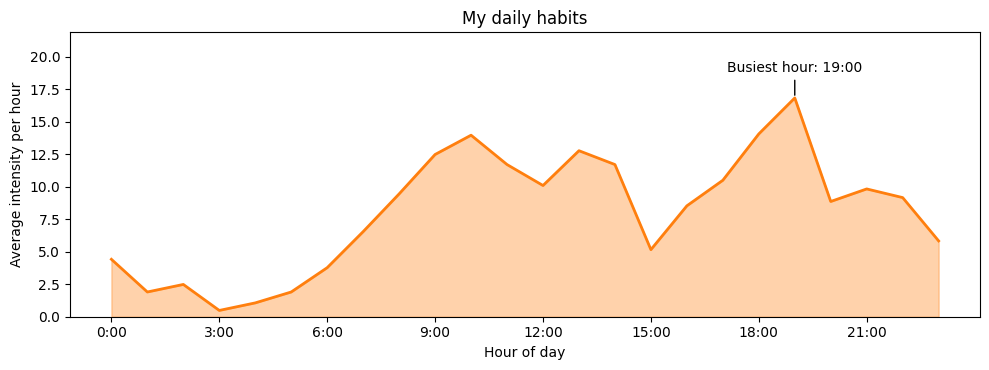

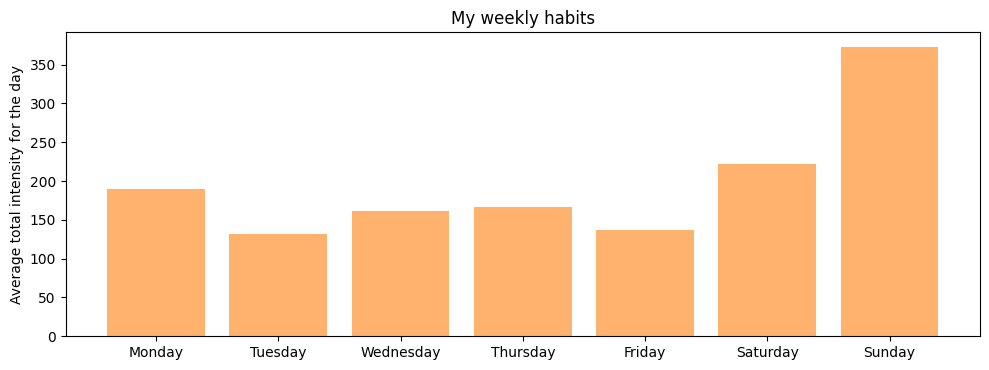

In [15]:
my_hours = hourly[hourly["Id"] == my_id].copy()
my_hours["Hour"]    = my_hours["ActivityHour"].dt.hour
my_hours["Date"]    = my_hours["ActivityHour"].dt.normalize()
my_hours["Weekday"] = my_hours["ActivityHour"].dt.day_name()

# Plot 1: daily habits (average hour-by-hour profile) 
by_hour = my_hours.groupby("Hour")["TotalIntensity"].mean().reindex(range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(by_hour.index, by_hour.values, color="C1", alpha=0.35)
ax.plot(by_hour.index, by_hour.values, color="C1", lw=2)

busiest = by_hour.idxmax()
ax.annotate(f"Busiest hour: {busiest}:00", xy=(busiest, by_hour.max()),
            xytext=(busiest, by_hour.max() * 1.12), ha="center", arrowprops=dict(arrowstyle="-"))
ax.set_ylim(0, by_hour.max() * 1.3)
ax.set_xticks(range(0, 24, 3)); ax.set_xticklabels([f"{h}:00" for h in range(0, 24, 3)])
ax.set_xlabel("Hour of day"); ax.set_ylabel("Average intensity per hour")
ax.set_title("My daily habits")
plt.tight_layout(); plt.show()

# Plot 2: weekly habits (total activity for each day of the week) 
day_totals = my_hours.groupby("Date").agg(
    total=("TotalIntensity", "sum"),
    hours=("TotalIntensity", "size"),
    Weekday=("Weekday", "first"),
)
day_totals = day_totals[day_totals["hours"] == 24]            # only fully recorded days

order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_weekday = day_totals.groupby("Weekday")["total"].mean().reindex(order)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(order, by_weekday.values, color="C1", alpha=0.6)
ax.set_ylabel("Average total intensity for the day")
ax.set_title("My weekly habits")
plt.tight_layout(); plt.show()

## 5. “Am I consistent?”
Show: how many days a week I was active, and the gap between my best and worst days.
Data: daily file.
Explore: the spread of daily activity per person. Two people with the same average can be very different: one steady, one weekend-only.

In [16]:
ACTIVE_DAY = 30      # a day counts as "active" with 30+ hard minutes

consistency = worn.groupby("Id").agg(
    days        = ("ActivityDay", "count"),
    active_days = ("ModVigMinutes", lambda s: (s >= ACTIVE_DAY).sum()),
)
consistency = consistency[consistency["days"] >= 14]
consistency["pct_active_days"] = consistency["active_days"] / consistency["days"] * 100

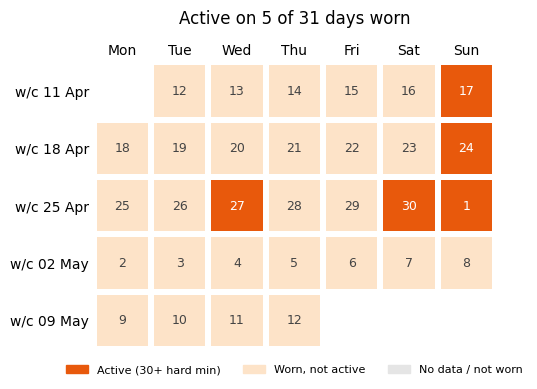

In [17]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

mine         = daily[daily["Id"] == my_id].set_index("ActivityDay")
days         = pd.date_range(daily["ActivityDay"].min(), daily["ActivityDay"].max())
first_monday = days[0] - pd.Timedelta(days=days[0].dayofweek)
n_weeks      = (days[-1] - first_monday).days // 7 + 1

# One square per day: 0 = no data / not worn, 1 = worn but not active, 2 = active
grid = np.full((n_weeks, 7), np.nan)
fig, ax = plt.subplots(figsize=(8, 4))
for day in days:
    row, col = (day - first_monday).days // 7, day.dayofweek
    if day not in mine.index or mine.loc[day, "SedentaryMinutes"] == 1440:
        grid[row, col] = 0
    elif mine.loc[day, "ModVigMinutes"] >= ACTIVE_DAY:
        grid[row, col] = 2
    else:
        grid[row, col] = 1
    ax.text(col + 0.5, row + 0.5, day.day, ha="center", va="center", fontsize=9,
            color="white" if grid[row, col] == 2 else "#444")

colours = ListedColormap(["#e5e5e5", "#fde3c8", "#e8590c"])
ax.pcolormesh(np.ma.masked_invalid(grid), cmap=colours, vmin=0, vmax=2, edgecolors="white", linewidth=3)
ax.set_aspect("equal"); ax.invert_yaxis(); ax.xaxis.tick_top(); ax.tick_params(length=0)
ax.set_xticks(np.arange(7) + 0.5); ax.set_xticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_yticks(np.arange(n_weeks) + 0.5)
ax.set_yticklabels([(first_monday + pd.Timedelta(weeks=w)).strftime("w/c %d %b") for w in range(n_weeks)])
for side in ax.spines.values(): side.set_visible(False)

ax.legend(handles=[Patch(color="#e8590c", label=f"Active ({ACTIVE_DAY}+ hard min)"),
                   Patch(color="#fde3c8", label="Worn, not active"),
                   Patch(color="#e5e5e5", label="No data / not worn")],
          loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, frameon=False, fontsize=8)
ax.set_title(f"Active on {(grid == 2).sum()} of {(grid > 0).sum()} days worn", pad=28)
plt.tight_layout(); plt.show()

## Limitations

- Data quality: non-wear days and partial days should be filtered or flagged, so a day where the tracker was off doesn’t show as a lazy day

# Potential Features

In [18]:
activity = pd.read_csv(FOLDER / "dailyActivity_merged.csv")
sleep    = pd.read_csv(FOLDER / "sleepDay_merged.csv")
activity["Date"] = pd.to_datetime(activity["ActivityDate"], format=DATE)
sleep["Date"]    = pd.to_datetime(sleep["SleepDay"], format=DATETIME).dt.normalize()
sleep = sleep.drop_duplicates(["Id", "Date"])                  # 3 days have two sleep rows

metrics = activity.merge(sleep[["Id", "Date", "TotalMinutesAsleep"]], on=["Id", "Date"], how="left")
metrics["steps"]          = metrics["TotalSteps"]
metrics["calories"]       = metrics["Calories"]
metrics["active_minutes"] = metrics["FairlyActiveMinutes"] + metrics["VeryActiveMinutes"]
metrics["sleep_hours"]    = metrics["TotalMinutesAsleep"] / 60

# Tracker not worn all day -> activity numbers are not real zeros, so mark them "no data"
not_worn = metrics["SedentaryMinutes"] == 1440
metrics.loc[not_worn, ["steps", "calories", "active_minutes"]] = np.nan
metrics = metrics[["Id", "Date", "steps", "calories", "active_minutes", "sleep_hours"]]

# The data stops mid-afternoon on the last day (median steps that day: ~3,400 vs ~7,900 normally),
# so that day would make every goal look "not met". Leave it out.
metrics = metrics[metrics["Date"] < metrics["Date"].max()]

LABELS = {"steps": "Steps", "calories": "Calories burned", "active_minutes": "Active minutes", "sleep_hours": "Sleep (hours)"}

def show(value, metric):
    """Format a number for display - or say 'No data' (requirement 8)."""
    if pd.isna(value): return "No data"
    return f"{value:.1f}" if metric == "sleep_hours" else f"{value:,.0f}"

### Personal goals

In [19]:
DEFAULT_GOALS = {"steps": 10000, "active_minutes": 30, "sleep_hours": 7}
USER_GOALS = {}      # users override here, e.g.  USER_GOALS[my_id] = {"steps": 8000}

def goals_for(user_id):
    goals = dict(DEFAULT_GOALS)
    # calories burned includes resting burn, which differs a lot per person -> start from their own typical day
    goals["calories"] = int(round(metrics.loc[metrics["Id"] == user_id, "calories"].median(), -2))
    goals.update(USER_GOALS.get(user_id, {}))
    return goals

print(goals_for(my_id))

{'steps': 10000, 'active_minutes': 30, 'sleep_hours': 7, 'calories': 1400}


### Daily summary

In [20]:
def daily_summary(user_id, date):
    row = metrics[(metrics["Id"] == user_id) & (metrics["Date"] == pd.Timestamp(date))]
    table = []
    for metric, target in goals_for(user_id).items():
        actual = row[metric].iloc[0] if len(row) else np.nan
        if pd.isna(actual):   status = "No data"
        elif actual >= target: status = "Met"
        else:                  status = "Not met"
        table.append({"Goal": LABELS[metric], "Actual": show(actual, metric), "Target": show(target, metric), "Status": status})
    return pd.DataFrame(table)

print(daily_summary(my_id, "2016-04-20"))
print(daily_summary(1503960366, "2016-04-20"))

              Goal   Actual  Target   Status
0            Steps    4,974  10,000  Not met
1   Active minutes        0      30  Not met
2    Sleep (hours)  No data     7.0  No data
3  Calories burned    1,446   1,400      Met
              Goal  Actual  Target   Status
0            Steps  10,544  10,000      Met
1   Active minutes      40      30      Met
2    Sleep (hours)     6.0     7.0  Not met
3  Calories burned   1,786   1,800  Not met


### Monthly overview

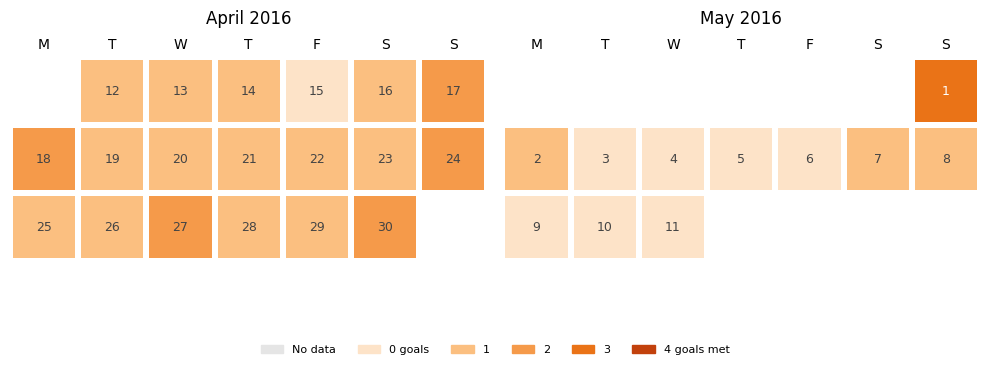

In [21]:
import calendar
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

def goals_met_per_day(user_id):
    """Number of goals met each day (days with no data at all are left out)."""
    mine = metrics[metrics["Id"] == user_id].set_index("Date")
    met = pd.DataFrame({m: mine[m] >= target for m, target in goals_for(user_id).items()})
    known = pd.DataFrame({m: mine[m].notna() for m in goals_for(user_id)})
    return met.sum(axis=1).where(known.any(axis=1)), known.sum(axis=1)

def month_calendar(user_id, year, month, ax):
    met, n_known = goals_met_per_day(user_id)
    first_weekday, n_days = calendar.monthrange(year, month)             # Monday = 0
    n_weeks = (first_weekday + n_days + 6) // 7
    grid = np.full((n_weeks, 7), np.nan)
    for day in range(1, n_days + 1):
        date = pd.Timestamp(year, month, day)
        if not (metrics["Date"].min() <= date <= metrics["Date"].max()):
            continue                                                     # outside the study period: leave blank
        row, col = (first_weekday + day - 1) // 7, (first_weekday + day - 1) % 7
        grid[row, col] = met.get(date, np.nan) if date in met.index and not np.isnan(met[date]) else -1   # -1 = no data
        ax.text(col + 0.5, row + 0.5, day, ha="center", va="center", fontsize=9,
                color="white" if grid[row, col] >= 3 else "#444")
    colours = ListedColormap(["#e5e5e5", "#fde3c8", "#fbbf80", "#f59a4a", "#ea7317", "#c2410c"])
    ax.pcolormesh(np.ma.masked_invalid(grid), cmap=colours, vmin=-1, vmax=4, edgecolors="white", linewidth=3)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.xaxis.tick_top(); ax.tick_params(length=0)
    ax.set_xticks(np.arange(7) + 0.5); ax.set_xticklabels(["M", "T", "W", "T", "F", "S", "S"])
    used_rows = np.where(~np.isnan(grid).all(axis=1))[0]                 # only show weeks that have data
    ax.set_ylim(used_rows.max() + 1, used_rows.min())
    ax.set_yticks([])
    for side in ax.spines.values(): side.set_visible(False)
    ax.set_title(calendar.month_name[month] + f" {year}", pad=24)

def calendar_figure(user_id):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    month_calendar(user_id, 2016, 4, axes[0]); month_calendar(user_id, 2016, 5, axes[1])
    shades = ["#e5e5e5", "#fde3c8", "#fbbf80", "#f59a4a", "#ea7317", "#c2410c"]
    names  = ["No data", "0 goals", "1", "2", "3", "4 goals met"]
    fig.legend(handles=[Patch(color=c, label=n) for c, n in zip(shades, names)], loc="lower center", ncol=6, frameon=False, fontsize=8)
    plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

calendar_figure(my_id)

### Friends leaderboard

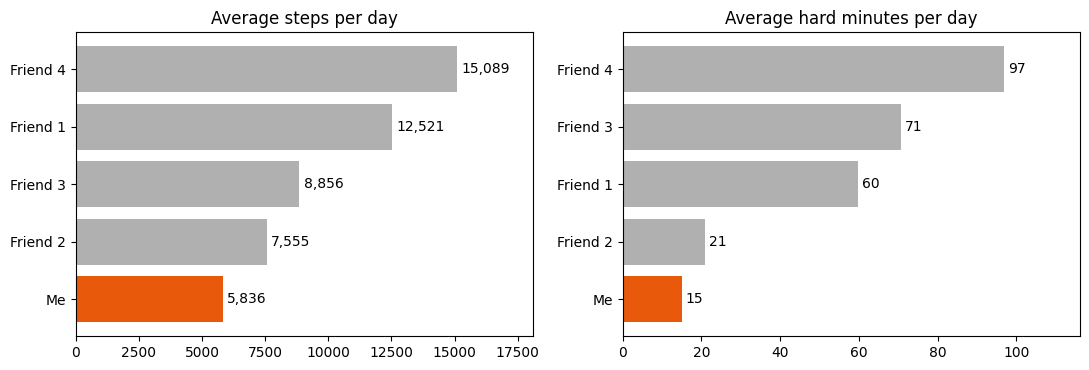

In [22]:
activity = pd.read_csv(FOLDER / "dailyActivity_merged.csv")
activity["Date"] = pd.to_datetime(activity["ActivityDate"], format=DATE)
activity["hard_minutes"] = activity["FairlyActiveMinutes"] + activity["VeryActiveMinutes"]

# Keep days the tracker was worn, and drop the last day (the data stops part-way through it)
worn = activity[(activity["SedentaryMinutes"] != 1440) & (activity["Date"] < activity["Date"].max())]

# Pick 5 people: me plus the 4 friends with the most data
friends = list(worn["Id"].value_counts().index.drop(my_id, errors="ignore")[:4])
names = {my_id: "Me"}
names.update({uid: f"Friend {i + 1}" for i, uid in enumerate(friends)})

# Average per day for each person
averages = worn[worn["Id"].isin(names)].groupby("Id")[["TotalSteps", "hard_minutes"]].mean()

# Two bar charts side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
charts = [("TotalSteps", "Average steps per day"), ("hard_minutes", "Average hard minutes per day")]

for ax, (column, title) in zip(axes, charts):
    data = averages[column].sort_values()                                   # lowest at the bottom
    bars = ax.barh([names[uid] for uid in data.index], data.values,
                   color=["#e8590c" if uid == my_id else "#b0b0b0" for uid in data.index])
    ax.bar_label(bars, labels=[f"{value:,.0f}" for value in data.values], padding=3)
    ax.set_title(title)
    ax.set_xlim(0, data.max() * 1.2)

plt.tight_layout(); plt.show()

### Streaks

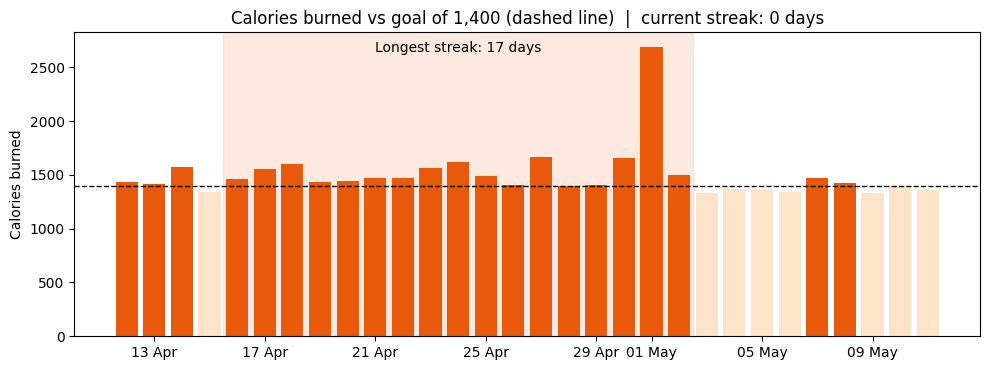

In [23]:
import matplotlib.dates as mdates

days = pd.date_range(metrics["Date"].min(), metrics["Date"].max())
calories = metrics[metrics["Id"] == my_id].set_index("Date")["calories"].reindex(days)   # missing days stay empty
goal = goals_for(my_id)["calories"]
met = calories >= goal                                     # a missing day counts as not met

run = met.groupby((~met).cumsum()).cumsum()                # counts 1, 2, 3... on days met, resets after a miss
longest, end = run.max(), run.idxmax()
start = end - pd.Timedelta(days=longest - 1)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(days, calories, color=["#e8590c" if m else "#fde3c8" for m in met])
ax.axhline(goal, color="black", ls="--", lw=1)
if longest >= 2:
    ax.axvspan(start - pd.Timedelta(hours=12), end + pd.Timedelta(hours=12), color="#e8590c", alpha=0.12)
    ax.text(start + (end - start) / 2, ax.get_ylim()[1] * 0.97, f"Longest streak: {longest} days", ha="center", va="top")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_ylabel("Calories burned")
ax.set_title(f"Calories burned vs goal of {goal:,} (dashed line)  |  current streak: {run.iloc[-1]} days")
plt.tight_layout(); plt.show()

### Weekday vs Weekend

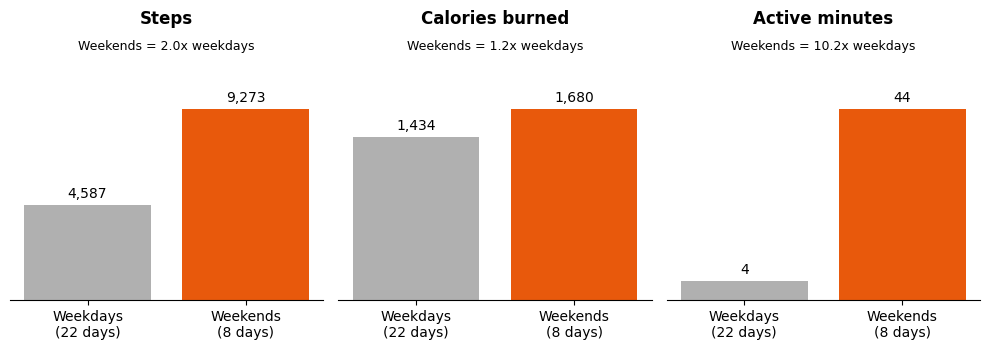

In [24]:
MIN_DAYS_EACH = 3      # need at least this many weekdays AND weekend days to compare

def weekend_chart(user_id):
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
    for ax, metric in zip(axes, ["steps", "calories", "active_minutes"]):
        mine = metrics[metrics["Id"] == user_id].dropna(subset=[metric])      # days with no data are left out
        is_weekend = mine["Date"].dt.dayofweek >= 5
        n_weekday, n_weekend = (~is_weekend).sum(), is_weekend.sum()
        ax.set_title(LABELS[metric], fontweight="bold")

        if min(n_weekday, n_weekend) < MIN_DAYS_EACH:                         # not enough days to compare
            ax.text(0.5, 0.5, "Not enough data", ha="center", va="center", color="grey", transform=ax.transAxes)
            ax.set_xticks([]); ax.set_yticks([])
            for side in ax.spines.values(): side.set_visible(False)
            continue

        weekday_avg, weekend_avg = mine.loc[~is_weekend, metric].mean(), mine.loc[is_weekend, metric].mean()
        bars = ax.bar([f"Weekdays\n({n_weekday} days)", f"Weekends\n({n_weekend} days)"],
                      [weekday_avg, weekend_avg], color=["#b0b0b0", "#e8590c"])
        ax.bar_label(bars, labels=[show(weekday_avg, metric), show(weekend_avg, metric)], padding=3)
        ax.set_ylim(0, max(weekday_avg, weekend_avg) * 1.4)
        ax.set_yticks([])
        for side in ["top", "right", "left"]: ax.spines[side].set_visible(False)
        ax.text(0.5, 0.97, f"Weekends = {weekend_avg / weekday_avg:.1f}x weekdays", ha="center", va="top", transform=ax.transAxes, fontsize=9)

    plt.tight_layout(); plt.show()

weekend_chart(my_id)

### Missing data

In [25]:
has_data   = metrics[list(LABELS)].notna()                       # True where a day has a value
n_days     = len(metrics)
n_users    = metrics["Id"].nunique()
users_with = has_data.groupby(metrics["Id"]).any().sum()         # users with at least one day of data

coverage = pd.DataFrame({
    "Days with data":      [f"{n} of {n_days}" for n in has_data.sum()],
    "% of days":           [f"{p:.0f}%" for p in has_data.mean() * 100],
    "Users with any data": [f"{n} of {n_users}" for n in users_with],
}, index=[LABELS[m] for m in LABELS])
coverage

,Days with data,% of days,Users with any data
Steps,842 of 919,92%,33 of 33
Calories burned,842 of 919,92%,33 of 33
Active minutes,842 of 919,92%,33 of 33
Sleep (hours),402 of 919,44%,24 of 33


**Notes**
- Last day dropped: the data ends mid-afternoon on 12 May, so I excluded that day. Left in, it made every goal look “not met” and made all current streaks show 0.
- Calories goal: “calories burned” includes the body’s resting burn, which ranges from about 1,400 to 3,600 a day across users. A single 2,000 goal would be meaningless, so the default is each person’s own typical day. Your group should decide how the goal is set.
- Not-worn days: on the 79 days with no tracker use, calories still show about 1,840, which would look like a real value. I mark steps, calories and active minutes as no data on those days.
- Calendar with missing sleep: the colour counts goals met out of those that have data, so users without sleep records can reach at most 3. You might show “3 of 3” instead, or grey out partial days.
- Streaks and missing days: a no-data day breaks a streak here, which is the cautious choice. Skipping them is the alternative.